# Minería de Datos – Práctica 3.3 Regresión
## Equipo 7
**Integrantes:** Flores García Claudio, Juarez Valdivia Barvara Caridad, Ortega de la Paz Rafael

**Datos:** *Vino contenido de alcohol* (178 muestras de vino y 13 mediciones químicas, una de ellas el contenido de alcohol).

**Algoritmos utilizados:** Regresión Lineal Múltiple, Lasso y Random Forest (Python); Regresión Lineal y Random Forest (RapidMiner).

## 1. Caso de negocio
Una bodega busca **predecir el contenido de alcohol de un vino a partir de sus características químicas**, como la acidez, el color, los fenoles, la prolina, entre otras. Con un buen modelo se puede:
- Estimar el grado de alcohol antes de terminar el proceso, permitiendo ajustar la fermentación o la mezcla.
- Identificar **qué características influyen más en el contenido de alcohol** para tener un mejor control durante la producción.
- Revisar la consistencia de los lotes: un vino cuyo alcohol real se aleja mucho del predicho merece revisión.

## 2. Variable objetivo
**Alcohol** (% de alcohol por volumen): es una **variable continua**, cuyos valores van de 11.03 a 14.83, y corresponde a la variable dependiente (Y) que se busca predecir.
Las otras 12 mediciones químicas son las variables independientes (X), ya que pueden ayudar a estimar el contenido de alcohol. La variable `Muestra` es solo un número de identificación y no se utiliza.



**Descripción de las variables independientes:**

| Variable | Qué mide |
|---|---|
| Ácido Málico | Ácido natural de la uva que aporta un sabor agrio y disminuye durante la maduración |
| Ceniza | Minerales que quedan al quemar el vino, vienen del suelo |
| Ceniza Alcalina | Parte de las cenizas que se relaciona con los minerales de carácter alcalino y el equilibrio de acidez |
| Magnesio | Mineral del vino, importante para el desarrollo de las levaduras durante la fermentación |
| Fenoles | Compuestos de la cáscara, las semillas y los tallos de la uva, dan color, cuerpo y astringencia |
| Flavonoides | Grupo de compuestos fenólicos que contribuyen al color, el sabor y otras propiedades del vino |
| Fenoles No Flavonoides | El resto de los fenoles, en cantidades pequeñas, influyen en el aroma y la estabilidad del vino |
| Protocianinas | Proantocianidinas (taninos condensados): dan la sensación áspera y permiten el añejamiento |
| Color Intenso | Intensidad del color del vino |
| Matiz | Tono del color: rojo-violeta (joven) o naranja (viejo) |
| Concentración Proteínas | Medición con luz ultravioleta (OD280/OD315) relacionada con proteínas y fenoles |
| Prolina | Aminoácido presente en la uva cuya concentración suele aumentar durante la maduración |

Se importan las librerías necesarias para realizar el análisis. Se utiliza **pandas** y **numpy** para trabajar con los datos, matplotlib y seaborn para generar gráficas, y scikit-learn para dividir los datos, estandarizar las variables, entrenar los modelos y evaluar sus resultados.
También se establece una semilla (SEMILLA = 42) para que los resultados se puedan reproducir cada vez que se ejecute el notebook.

In [1]:
import os, warnings, datetime
warnings.filterwarnings('ignore')
# Ocultar el aviso interno de Colab
try:
    import jupyter_client.session as _jcs
    _jcs.utcnow = lambda _dt=datetime: _dt.datetime.now(_dt.timezone.utc)
except Exception:
    pass

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_validate, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, LassoCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

pd.set_option('display.float_format', lambda x: f'{x:,.3f}')
sns.set_theme(style='whitegrid')
SEMILLA = 42

## 3. Carga y limpieza de datos

Se carga el archivo CSV, así como se verifica si existen valores nulos, registros duplicados, etc. Finalmente, se separa la variable objetivo de las variables independientes y se elimina *Muestra*, ya que únicamente sirve como identificador de cada registro.

In [2]:
# Busca el CSV en Colab (/content/) o en la misma carpeta del notebook
CANDIDATOS = ['/content/vino_contenido de alcohol.csv',
              'vino_contenido de alcohol.csv',
              'vino_contenido_de_alcohol.csv']
RUTA = next((r for r in CANDIDATOS if os.path.exists(r)), None)
if RUTA is None:
    raise FileNotFoundError('No se encontró el CSV. En Colab, súbanlo con el ícono de carpeta; '
                            'en local, déjenlo en la misma carpeta que este notebook.')
df = pd.read_csv(RUTA)
print('Archivo:', RUTA)
print('Filas:', df.shape[0], '| Columnas:', df.shape[1])
df.head()

Archivo: vino_contenido de alcohol.csv
Filas: 178 | Columnas: 14


,Muestra,Alcohol,Acido Malico,Ceniza,Ceniza Alcalina,Magnesio,Fenoles,Flavonoides,No Flavoniodes Fenosl,Protocianinas,Color Intenso,Matiz,Concentracion Proteinas,Prolina
0,1,14.230,1.710,2.430,15.600,127,2.800,3.060,0.280,2.290,5.640,1.040,3.920,1065
1,2,13.240,2.590,2.870,21.000,118,2.800,2.690,0.390,1.820,4.320,1.040,2.930,735
2,3,13.160,2.360,2.670,18.600,101,2.800,3.240,0.300,2.810,5.680,1.030,3.170,1185
3,4,14.100,2.020,2.400,18.800,103,2.750,2.920,0.320,2.380,6.200,1.070,2.750,1060
4,5,12.430,1.530,2.290,21.500,86,2.740,3.150,0.390,1.770,3.940,0.690,2.840,352


In [3]:
# Limpieza de nombres: quitar espacios sobrantes ('Matiz ') y corregir el error de captura 'No Flavoniodes Fenosl'
df.columns = df.columns.str.strip()
df = df.rename(columns={'No Flavoniodes Fenosl': 'Fenoles No Flavonoides'})

print('Valores nulos   :', int(df.isna().sum().sum()))
print('Filas duplicadas:', int(df.duplicated().sum()))
print('Tipos de datos  :', df.dtypes.value_counts().to_dict())

OBJETIVO = 'Alcohol'
datos = df.drop(columns=['Muestra'])            # identificador, no aporta información
VARIABLES = [c for c in datos.columns if c != OBJETIVO]
print('\nVariable objetivo:', OBJETIVO)
print('Variables independientes (', len(VARIABLES), '):', VARIABLES)

Valores nulos   : 0
Filas duplicadas: 0
Tipos de datos  : {dtype('float64'): 11, dtype('int64'): 3}

Variable objetivo: Alcohol
Variables independientes ( 12 ): ['Acido Malico', 'Ceniza', 'Ceniza Alcalina', 'Magnesio', 'Fenoles', 'Flavonoides', 'Fenoles No Flavonoides', 'Protocianinas', 'Color Intenso', 'Matiz', 'Concentracion Proteinas', 'Prolina']


## 4. Análisis exploratorio (EDA)
Se analizan los datos para conocer la distribución de las variables, identificar valores atípicos y observar qué características químicas tienen mayor relación con el contenido de alcohol. Esto permite comprender mejor los datos antes de entrenar los modelos.

### 4.1 Estadísticas descriptivas
Se calculan el promedio, la desviación estándar, los valores mínimo y máximo, y los cuartiles para conocer los rangos y la variabilidad de las variables.

In [4]:
datos.describe().T

,count,mean,std,min,25%,50%,75%,max
Alcohol,178.000,13.001,0.812,11.030,12.362,13.050,13.678,14.830
Acido Malico,178.000,2.336,1.117,0.740,1.603,1.865,3.083,5.800
Ceniza,178.000,2.367,0.274,1.360,2.210,2.360,2.558,3.230
Ceniza Alcalina,178.000,19.495,3.340,10.600,17.200,19.500,21.500,30.000
Magnesio,178.000,99.742,14.282,70.000,88.000,98.000,107.000,162.000
Fenoles,178.000,2.295,0.626,0.980,1.742,2.355,2.800,3.880
Flavonoides,178.000,2.029,0.999,0.340,1.205,2.135,2.875,5.080
Fenoles No Flavonoides,178.000,0.362,0.124,0.130,0.270,0.340,0.438,0.660
Protocianinas,178.000,1.591,0.572,0.410,1.250,1.555,1.950,3.580
Color Intenso,178.000,5.058,2.318,1.280,3.220,4.690,6.200,13.000


Las variables están en escalas muy distintas (Prolina va de 278 a 1,680 y Fenoles No Flavonoides de 0.13 a 0.66).
Por eso, antes de los modelos lineales se estandarizan con `StandardScaler` (media 0 y desviación estándar 1); Random Forest no lo necesita porque sus cortes no dependen de la escala.

### 4.2 Distribución de la variable objetivo

Se utilizan un histograma y un diagrama de caja para observar cómo se distribuye el contenido de alcohol e identificar posibles valores extremos.

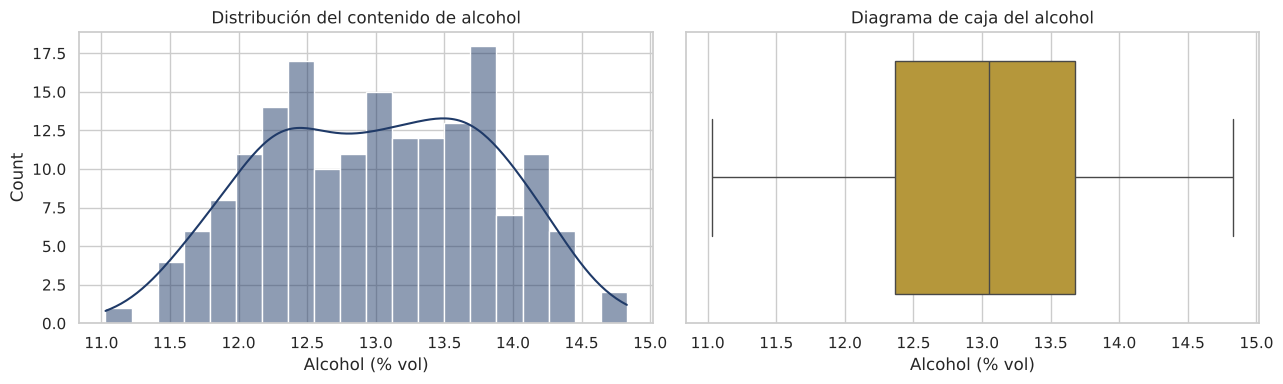

Media: 13.00  |  Mediana: 13.05  |  Mín: 11.03  |  Máx: 14.83


In [5]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(datos[OBJETIVO], bins=20, kde=True, color='#1F3A68', ax=ax[0])
ax[0].set_title('Distribución del contenido de alcohol'); ax[0].set_xlabel('Alcohol (% vol)')
sns.boxplot(x=datos[OBJETIVO], color='#C9A227', ax=ax[1])
ax[1].set_title('Diagrama de caja del alcohol'); ax[1].set_xlabel('Alcohol (% vol)')
plt.tight_layout(); plt.show()
print(f"Media: {datos[OBJETIVO].mean():.2f}  |  Mediana: {datos[OBJETIVO].median():.2f}  |  Mín: {datos[OBJETIVO].min():.2f}  |  Máx: {datos[OBJETIVO].max():.2f}")

**Interpretación:** el contenido de alcohol tiene una distribución aproximadamente simétrica (media 13.00 y mediana 13.05, casi iguales; asimetría ≈ −0.05). Es una distribución ancha, con dos ligeros picos (≈ 12.4 y ≈ 13.8 % vol) que pueden deberse a la mezcla de distintos tipos de vino. La mitad central de los vinos está entre 12.4 y 13.7 % vol, y el diagrama de caja no muestra valores atípicos, así que la variable objetivo se usa tal cual, sin transformaciones.

### 4.3 Distribución de las variables independientes

Se grafica un histograma por variable para ver su forma, y un diagrama de caja con los valores estandarizados
para comparar todas en la misma escala y detectar valores atípicos (|z| > 3).

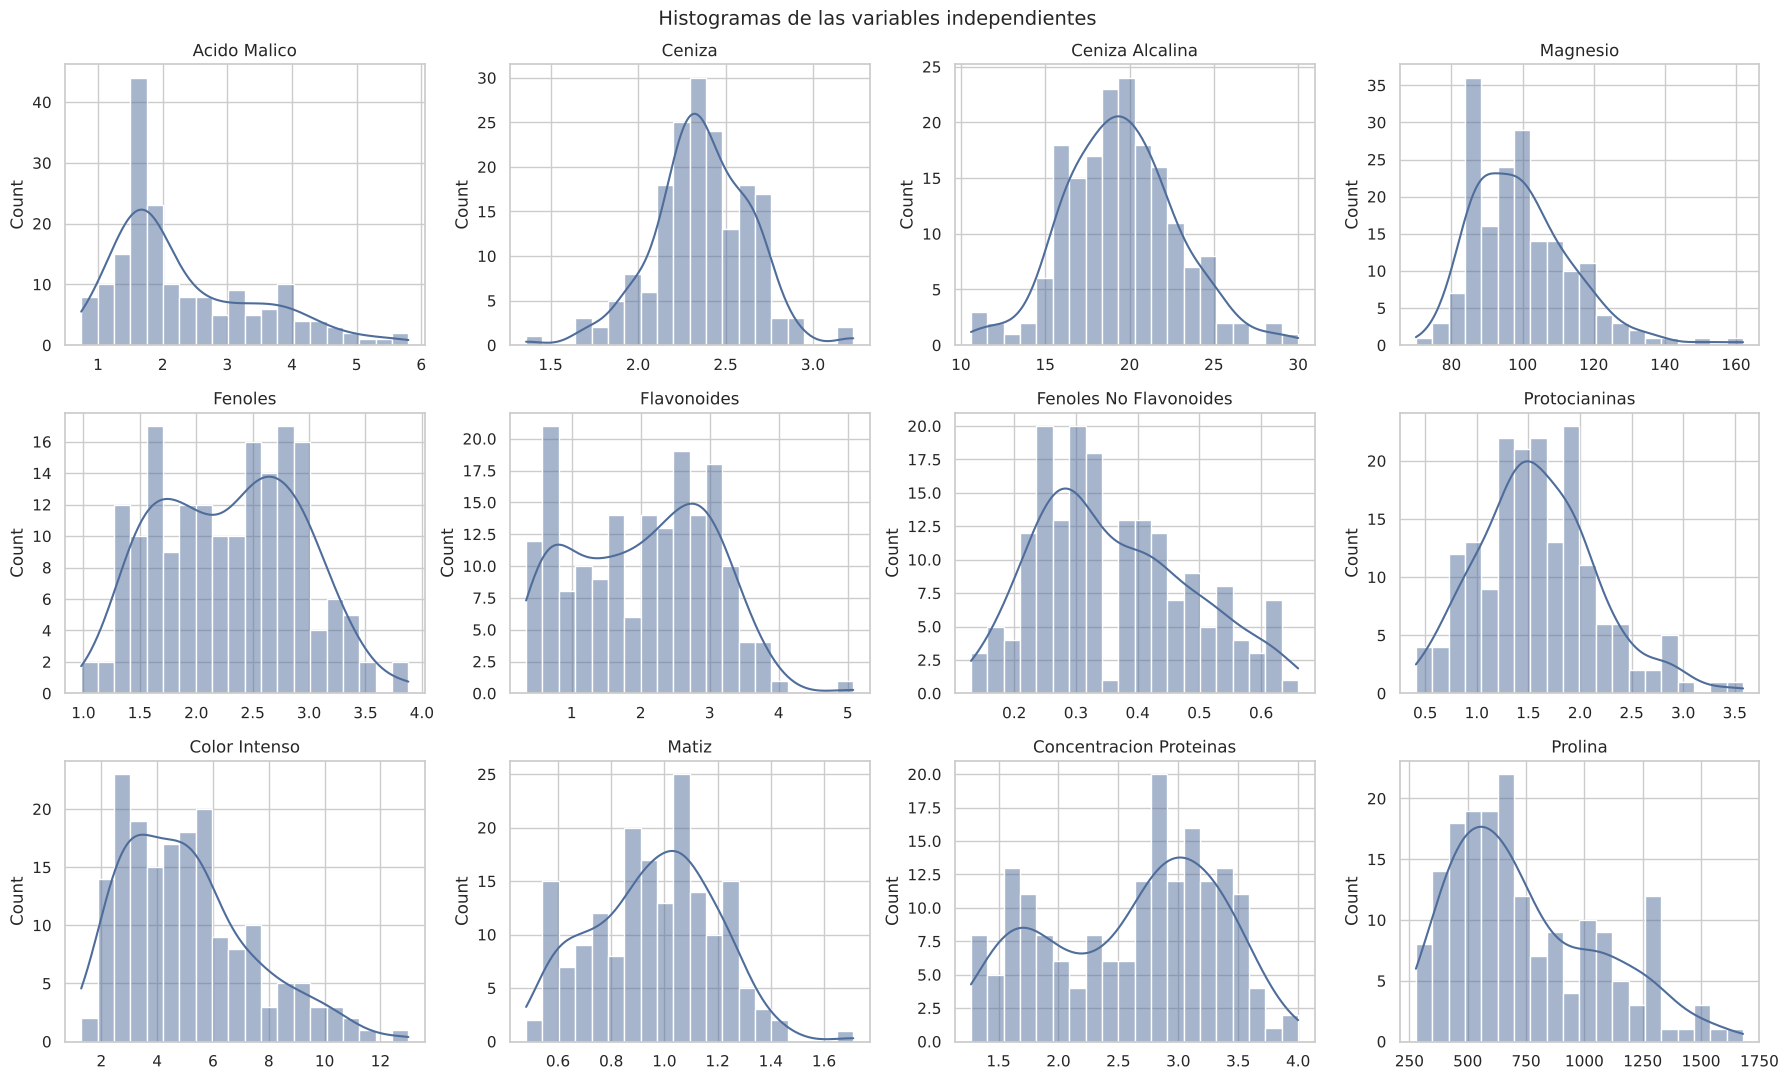

In [6]:
fig, axes = plt.subplots(3, 4, figsize=(18, 11))
for ax, v in zip(axes.ravel(), VARIABLES):
    sns.histplot(datos[v], bins=20, kde=True, color='#4F6D9A', ax=ax)
    ax.set_title(v); ax.set_xlabel('')
plt.suptitle('Histogramas de las variables independientes', fontsize=14); plt.tight_layout(); plt.show()

**Interpretación:**
- **Ceniza, Ceniza Alcalina y Matiz** tienen forma de campana, cercana a la normal.
- **Fenoles, Flavonoides y Concentración de Proteínas** son **bimodales** (dos picos), lo que sugiere que en los datos hay grupos de vinos con perfiles químicos distintos.
- **Magnesio, Ácido Málico, Color Intenso y Prolina** tienen sesgo a la derecha (asimetría entre 0.8 y 1.1): la mayoría de los vinos tiene valores bajos o medios y unos pocos tienen valores muy altos. Por eso se revisan los valores atípicos a continuación.

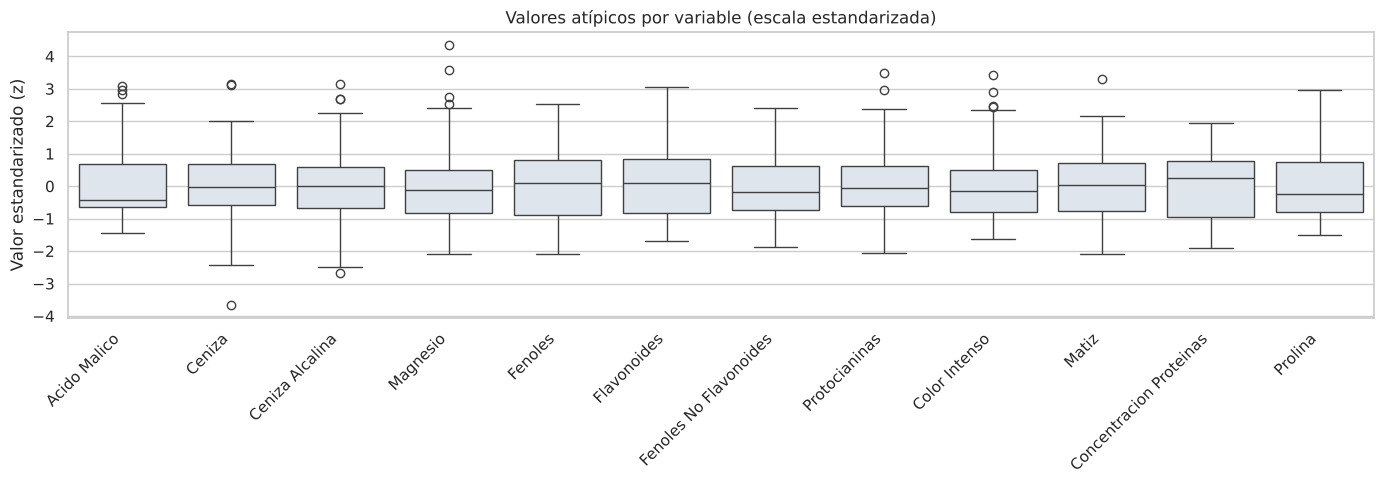

Puntos con |z| > 3 por variable:
Acido Malico       1
Ceniza             3
Ceniza Alcalina    1
Magnesio           2
Flavonoides        1
Protocianinas      1
Color Intenso      1
Matiz              1
dtype: int64


In [7]:
# Valores atípicos: diagrama de caja con las variables estandarizadas (misma escala)
z = (datos[VARIABLES] - datos[VARIABLES].mean()) / datos[VARIABLES].std()
plt.figure(figsize=(14, 5))
sns.boxplot(data=z, color='#DCE4F0')
plt.xticks(rotation=45, ha='right'); plt.ylabel('Valor estandarizado (z)')
plt.title('Valores atípicos por variable (escala estandarizada)'); plt.tight_layout(); plt.show()
print('Puntos con |z| > 3 por variable:')
print((z.abs() > 3).sum()[lambda s: s > 0])

Se identifican 11 valores atípicos distribuidos en 8 variables, principalmente en Ceniza y Magnesio. Como son mediciones químicas posibles y solo se cuenta con 178 muestras, se conservan para no perder información importante.

### 4.4 Correlación con el alcohol

Se utiliza la correlación de Pearson para identificar las variables más relacionadas con el contenido de alcohol.

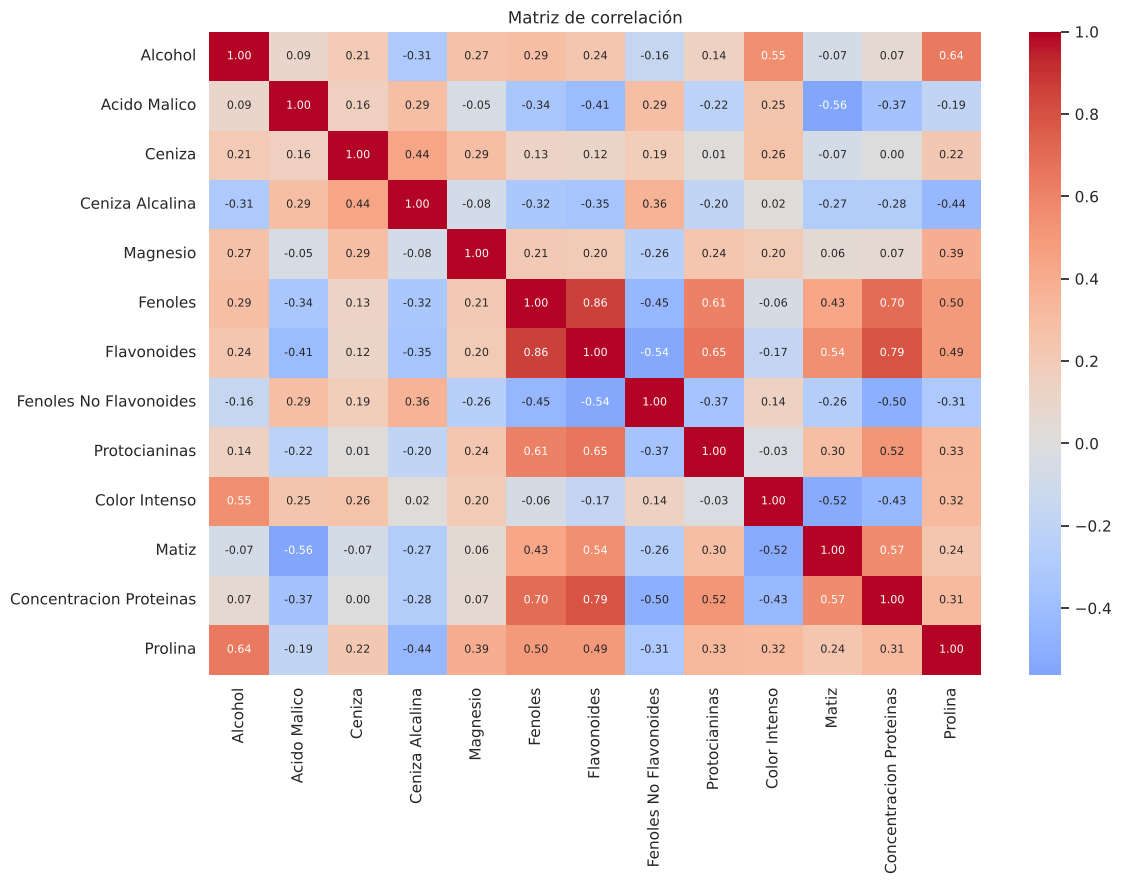

In [8]:
corr = datos.corr()
plt.figure(figsize=(12, 9))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, annot_kws={'size': 8})
plt.title('Matriz de correlación'); plt.tight_layout(); plt.show()

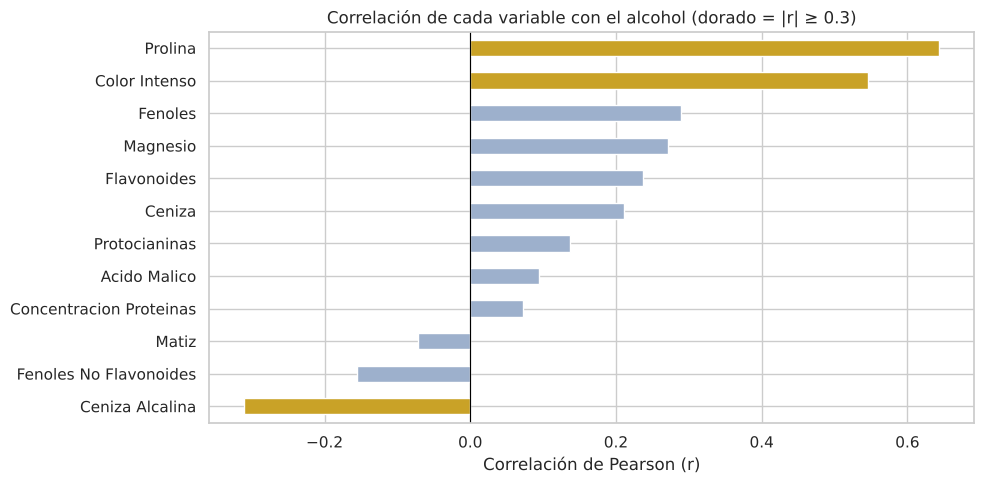

,r con Alcohol
Prolina,0.644
Color Intenso,0.546
Ceniza Alcalina,-0.310
Fenoles,0.289
Magnesio,0.271
Flavonoides,0.237
Ceniza,0.212
Fenoles No Flavonoides,-0.156
Protocianinas,0.137
Acido Malico,0.094


In [9]:
corr_obj = corr[OBJETIVO].drop(OBJETIVO).sort_values()
plt.figure(figsize=(10, 5))
colores = ['#C9A227' if abs(v) >= 0.3 else '#9DB0CC' for v in corr_obj]
corr_obj.plot.barh(color=colores)
plt.axvline(0, color='black', lw=0.8)
plt.title('Correlación de cada variable con el alcohol (dorado = |r| ≥ 0.3)'); plt.xlabel('Correlación de Pearson (r)')
plt.tight_layout(); plt.show()
corr_obj.sort_values(key=abs, ascending=False).rename('r con Alcohol').to_frame()

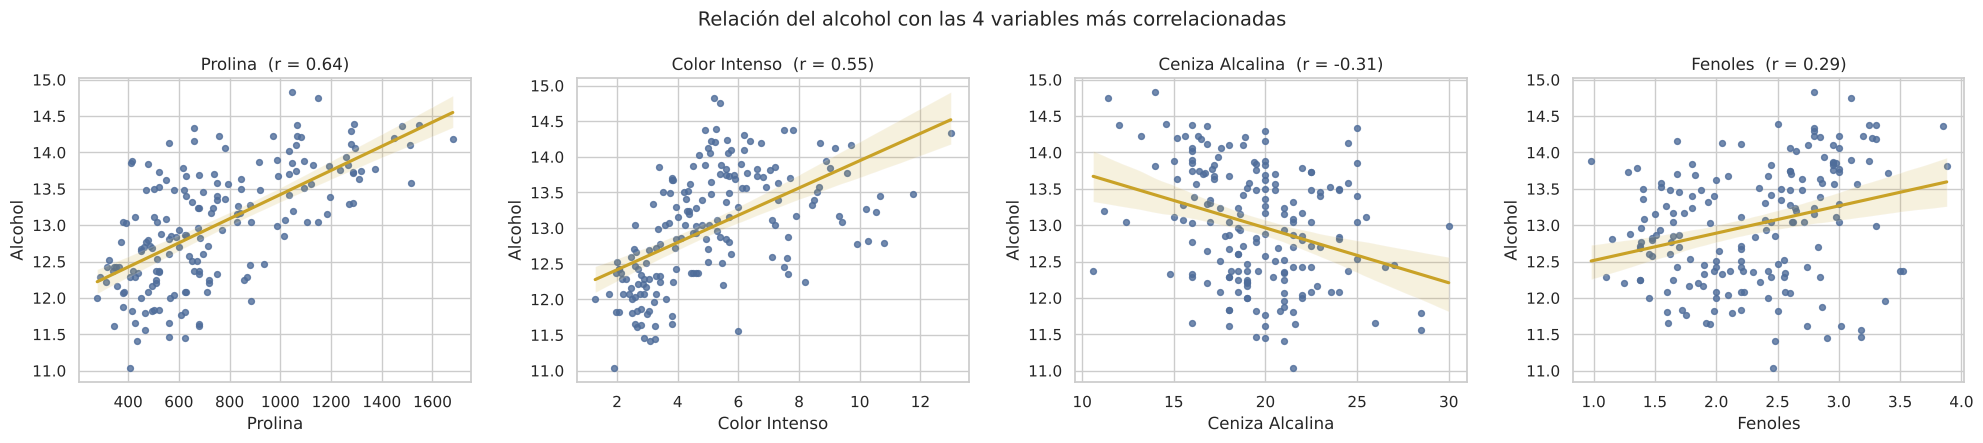

In [10]:
top4 = corr_obj.abs().sort_values(ascending=False).index[:4]
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
for ax, v in zip(axes, top4):
    sns.regplot(x=datos[v], y=datos[OBJETIVO], ax=ax, scatter_kws={'s': 18, 'color': '#4F6D9A'}, line_kws={'color': '#C9A227'})
    ax.set_title(f'{v}  (r = {corr_obj[v]:.2f})')
plt.suptitle('Relación del alcohol con las 4 variables más correlacionadas', fontsize=14); plt.tight_layout(); plt.show()

**Lectura del EDA:**
- **Prolina (r = 0.64)** y **Color Intenso (r = 0.55)** son las variables más relacionadas con el alcohol: a más prolina  y más color, más alcohol.
- **Ceniza Alcalina (r = −0.31)** es la relación negativa más clara.
- Varias variables casi no tienen relación lineal (Matiz, Concentración de Proteínas, Ácido Málico).
- Hay **variables muy correlacionadas entre sí**: Fenoles y Flavonoides (r = 0.86), Flavonoides y Concentración de
  Proteínas (0.79).

### 4.5 Multicolinealidad (VIF)
Como hay variables muy correlacionadas entre sí, se calcula el **factor de inflación de la varianza (VIF)**. Indica cuánto se "infla" la incertidumbre del coeficiente de una variable por estar correlacionada con las demás. Como referencia, un VIF > 10 indica multicolinealidad grave.

In [11]:
# VIF = diagonal de la inversa de la matriz de correlación de las variables independientes
vif = pd.Series(np.diag(np.linalg.inv(datos[VARIABLES].corr().values)), index=VARIABLES, name='VIF')
vif.sort_values(ascending=False).to_frame()

,VIF
Flavonoides,7.029
Fenoles,4.331
Concentracion Proteinas,3.737
Matiz,2.542
Color Intenso,2.493
Prolina,2.442
Ceniza,2.180
Ceniza Alcalina,2.179
Protocianinas,1.947
Fenoles No Flavonoides,1.794


**Interpretación:** el VIF más alto es el de Flavonoides (≈ 7.0), seguido de Fenoles (≈ 4.3). Todos están por debajo de 10, así que la multicolinealidad es **moderada** y no impide usar las 12 variables. Sin embargo, sí hay que tener cuidado al interpretar los coeficientes individuales de Flavonoides y Fenoles en la regresión lineal. Lasso ayuda en esto, porque tiende a quedarse con una sola de las variables redundantes.

### 4.6 Decisión de variables
Se dividen los datos en 80% entrenamiento y 20% prueba. Para decidir si conviene quitar las variables poco correlacionadas, se compara un modelo lineal con las 12 variables contra uno solo con las variables con |r| ≥ 0.2, usando **validación cruzada de 5 particiones solo con los datos de entrenamiento**. El conjunto de prueba se reserva para la evaluación final: si se usara para decidir, la evaluación final dejaría de ser imparcial.

In [12]:
X = datos[VARIABLES]
y = datos[OBJETIVO]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEMILLA)
print(f'Entrenamiento: {len(X_train)} muestras | Prueba: {len(X_test)} muestras')

# Variables con |r| >= 0.2, calculadas solo con los datos de entrenamiento
r_train = X_train.corrwith(y_train)
seleccion = r_train[r_train.abs() >= 0.2].index.tolist()
print('Variables con |r| >= 0.2:', seleccion)

kf = KFold(n_splits=5, shuffle=True, random_state=SEMILLA)
filas = []
for nombre, cols in [('Todas (12)', VARIABLES), (f'|r| ≥ 0.2 ({len(seleccion)})', seleccion)]:
    cv = cross_validate(make_pipeline(StandardScaler(), LinearRegression()), X_train[cols], y_train,
                        cv=kf, scoring=('neg_mean_squared_error', 'r2'))
    filas.append({'Variables': nombre,
                  'MSE (VC entrenamiento)': -cv['test_neg_mean_squared_error'].mean(),
                  'R² (VC entrenamiento)': cv['test_r2'].mean()})
pd.DataFrame(filas).set_index('Variables')

Entrenamiento: 142 muestras | Prueba: 36 muestras
Variables con |r| >= 0.2: ['Ceniza', 'Ceniza Alcalina', 'Magnesio', 'Fenoles', 'Flavonoides', 'Color Intenso', 'Prolina']


,MSE (VC entrenamiento),R² (VC entrenamiento)
Variables,,
Todas (12),0.360,0.464
|r| ≥ 0.2 (7),0.358,0.467


**Decisión: se usan las 12 variables.** Con validación cruzada, los dos conjuntos dan prácticamente el mismo resultado (MSE ≈ 0.36 y R² ≈ 0.46–0.47): quitar las variables de baja correlación **no mejora** el modelo. Además, el filtro por correlación simple no es un buen criterio de selección. Descarta Ácido Málico (r ≈ 0.1), que combinado con las demás sí aporta (Lasso lo conserva), y conserva Ceniza, Magnesio y Flavonoides, que Lasso termina eliminando. Por eso se deja que **Lasso haga la selección de variables de forma formal** (sección 6) y que Random Forest asigne la importancia de cada una.

## 5. Algoritmos de regresión
Se entrenan y comparan tres algoritmos utilizando el 80% de los datos para entrenamiento y el 20% restante para evaluar su desempeño (36 vinos que los modelos no vieron):

| Algoritmo | Idea |
|---|---|
| **Regresión Lineal Múltiple** | Predice el contenido de alcohol mediante una combinación lineal de las variables químicas |
| **Lasso** | Aplica una penalización que reduce algunos coeficientes a cero y permite seleccionar variables relevantes |
| **Random Forest** | Combina múltiples árboles de decisión para identificar relaciones lineales y no lineales en los datos |

In [13]:
modelos = {
    'Regresión Lineal Múltiple': make_pipeline(StandardScaler(), LinearRegression()),
    'Lasso': make_pipeline(StandardScaler(), LassoCV(cv=5, random_state=SEMILLA)),
    'Random Forest': RandomForestRegressor(n_estimators=300, random_state=SEMILLA),
}
predicciones = {}
for nombre, modelo in modelos.items():
    modelo.fit(X_train, y_train)
    predicciones[nombre] = modelo.predict(X_test)
print('Alpha elegido para Lasso:', round(modelos['Lasso'][-1].alpha_, 4))

Alpha elegido para Lasso: 0.0657


El valor de penalización de Lasso (α) no se fijó a mano: `LassoCV` lo eligió con validación cruzada de 5 particiones dentro del entrenamiento (α ≈ 0.066). Con ese valor, Lasso lleva a cero los coeficientes de las variables que no aportan información adicional.

### 5.1 Ecuación de la regresión lineal múltiple (variables en sus unidades originales)
Se entrena la misma regresión lineal sin estandarizar para obtener la ecuación en unidades reales. Esta es la forma en que la bodega usaría el modelo: sustituir las mediciones de un vino para estimar su alcohol.

In [14]:
lineal_original = LinearRegression().fit(X_train, y_train)
terminos = ' '.join(f"{'+' if b >= 0 else '-'} {abs(b):.4f}·{v}" for v, b in zip(VARIABLES, lineal_original.coef_))
print(f'Alcohol = {lineal_original.intercept_:.3f} {terminos}')

Alcohol = 11.395 + 0.1238·Acido Malico + 0.2466·Ceniza - 0.0445·Ceniza Alcalina - 0.0028·Magnesio + 0.0469·Fenoles + 0.0414·Flavonoides - 0.3603·Fenoles No Flavonoides - 0.1487·Protocianinas + 0.1626·Color Intenso + 0.2542·Matiz + 0.0943·Concentracion Proteinas + 0.0010·Prolina


**Interpretación:** cada coeficiente indica cuánto cambia el alcohol (% vol) cuando esa variable aumenta una unidad y las demás se mantienen constantes. Por ejemplo, +1 unidad de Color Intenso aumenta el alcohol estimado en ≈ 0.16 % vol, y +100 unidades de Prolina lo aumentan en ≈ 0.10 % vol. Estos coeficientes **no se pueden comparar entre sí** para saber qué variable es más importante, porque cada variable tiene unidades y rangos distintos: el coeficiente de Prolina parece pequeño (0.001) solo porque sus valores van de 278 a 1,680. Para comparar la importancia se usan los coeficientes estandarizados de la sección 6.

## 6. Variables independientes de mayor participación
Se comparan tres formas de medir la importancia:
- **Coeficientes estandarizados** de la regresión lineal: cuánto cambia el alcohol (en % vol) cuando la variable sube una desviación estándar.
- **Coeficientes de Lasso**: los que quedan en 0 son variables que Lasso eliminó.
- **Importancia de Random Forest**: qué tanto ayuda cada variable a reducir el error en los árboles (suma 1).

In [15]:
importancia = pd.DataFrame({
    'Coef. lineal (estandarizado)': modelos['Regresión Lineal Múltiple'][-1].coef_,
    'Coef. Lasso': modelos['Lasso'][-1].coef_,
    'Importancia Random Forest': modelos['Random Forest'].feature_importances_,
}, index=VARIABLES).sort_values('Importancia Random Forest', ascending=False)
importancia

,Coef. lineal (estandarizado),Coef. Lasso,Importancia Random Forest
Color Intenso,0.357,0.252,0.419
Prolina,0.311,0.349,0.214
Fenoles,0.030,0.012,0.059
Ceniza,0.068,0.000,0.052
Protocianinas,-0.089,-0.000,0.047
Ceniza Alcalina,-0.147,-0.045,0.036
Matiz,0.057,-0.000,0.034
Acido Malico,0.140,0.020,0.032
Concentracion Proteinas,0.066,0.000,0.031
Flavonoides,0.041,0.000,0.030


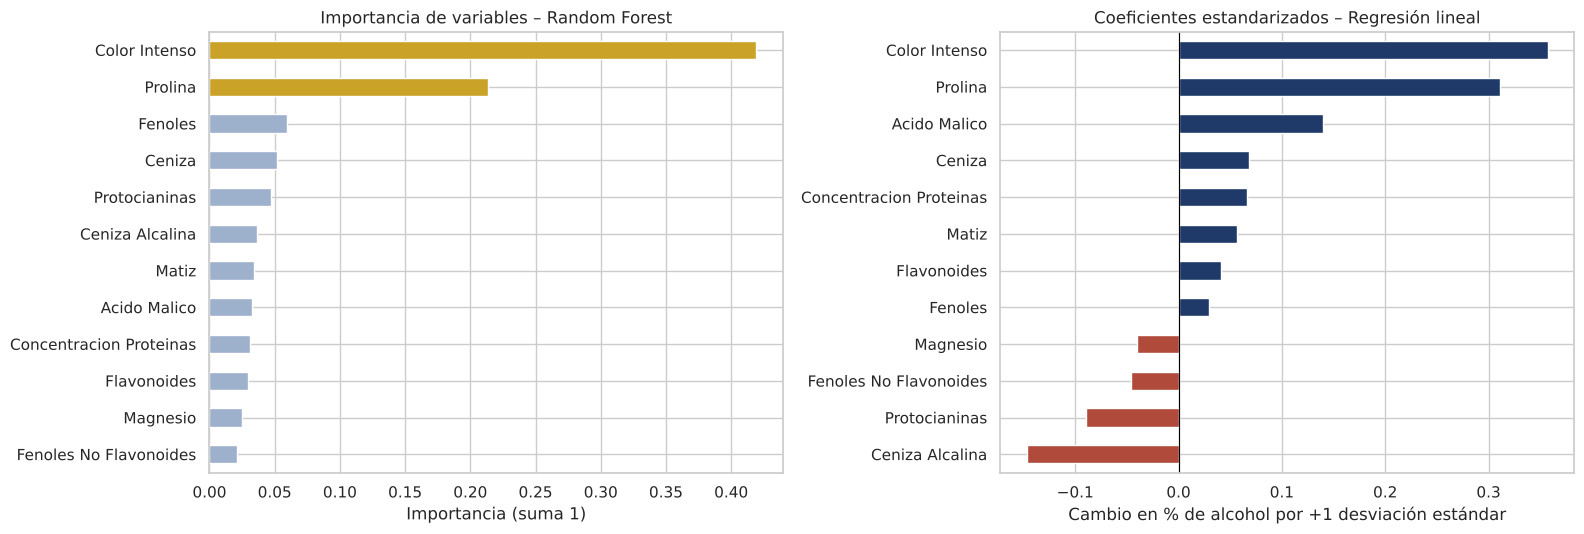

Variables que Lasso eliminó (coeficiente = 0): ['Ceniza', 'Protocianinas', 'Matiz', 'Concentracion Proteinas', 'Flavonoides', 'Magnesio', 'Fenoles No Flavonoides']


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
imp_rf = importancia['Importancia Random Forest'].sort_values()
imp_rf.plot.barh(ax=axes[0], color=['#C9A227' if v >= 0.1 else '#9DB0CC' for v in imp_rf])
axes[0].set_title('Importancia de variables – Random Forest'); axes[0].set_xlabel('Importancia (suma 1)')
coef = importancia['Coef. lineal (estandarizado)'].sort_values()
coef.plot.barh(ax=axes[1], color=['#1F3A68' if v >= 0 else '#B04A3A' for v in coef])
axes[1].axvline(0, color='black', lw=0.8)
axes[1].set_title('Coeficientes estandarizados – Regresión lineal'); axes[1].set_xlabel('Cambio en % de alcohol por +1 desviación estándar')
plt.tight_layout(); plt.show()
eliminadas = importancia.index[importancia['Coef. Lasso'].abs() < 1e-6].tolist()
print('Variables que Lasso eliminó (coeficiente = 0):', eliminadas)

**Interpretación:**
- **Color Intenso y Prolina** son las variables de mayor participación en los tres métodos. Tienen los coeficientes estandarizados más altos (+0.36 y +0.31 % vol por cada desviación estándar), los mayores coeficientes de Lasso (0.25 y 0.35) y juntas suman ≈ 63% de la importancia en Random Forest (42% y 21%).
- En el modelo lineal también pesan **Ceniza Alcalina** (−0.15, la única relación negativa relevante) y **Ácido Málico** (+0.14). En Random Forest su importancia es baja (≈ 3–4%).
- **Lasso eliminó 7 de las 12 variables** y conservó solo 5: Color Intenso, Prolina, Ceniza Alcalina, Ácido Málico y Fenoles. Entre las eliminadas están Flavonoides y Concentración de Proteínas, que son redundantes con Fenoles (VIF alto).

## 7. Validación del modelo: MSE y R²
Se evalúa el desempeño de los modelos mediante las siguientes métricas:
- **MSE**: mide el error cuadrático promedio (en (% vol)²); cuanto menor sea, mejor.
- **RMSE**: raíz del MSE; representa el error típico de predicción en las mismas unidades que el alcohol.
- **MAE**: mide el error absoluto promedio.
- **R²**: indica qué proporción de la variación del alcohol explica el modelo; cuanto más cercano a 1, mejor.

Las métricas se calculan en los datos de prueba. También se reporta el R² en entrenamiento, para detectar sobreajuste, y el MSE y R² de una **validación cruzada de 5 particiones** (media ± desviación estándar), para comprobar la estabilidad de los resultados con diferentes divisiones de los datos.

In [17]:
filas = []
for nombre, modelo in modelos.items():
    p = predicciones[nombre]
    cv = cross_validate(modelo, X, y, cv=kf, scoring=('neg_mean_squared_error', 'r2'))
    filas.append({'Algoritmo': nombre,
                  'MSE': mean_squared_error(y_test, p),
                  'RMSE (% vol)': np.sqrt(mean_squared_error(y_test, p)),
                  'MAE (% vol)': mean_absolute_error(y_test, p),
                  'R²': r2_score(y_test, p),
                  'R² entrenamiento': r2_score(y_train, modelo.predict(X_train)),
                  'MSE VC': -cv['test_neg_mean_squared_error'].mean(),
                  'R² VC': cv['test_r2'].mean(),
                  'R² VC (desv.)': cv['test_r2'].std()})
metricas = pd.DataFrame(filas).set_index('Algoritmo').sort_values('MSE')
metricas

,MSE,RMSE (% vol),MAE (% vol),R²,R² entrenamiento,MSE VC,R² VC,R² VC (desv.)
Algoritmo,,,,,,,,
Random Forest,0.121,0.347,0.275,0.770,0.932,0.303,0.546,0.126
Regresión Lineal Múltiple,0.167,0.409,0.349,0.682,0.572,0.325,0.509,0.108
Lasso,0.174,0.418,0.350,0.668,0.526,0.318,0.520,0.093


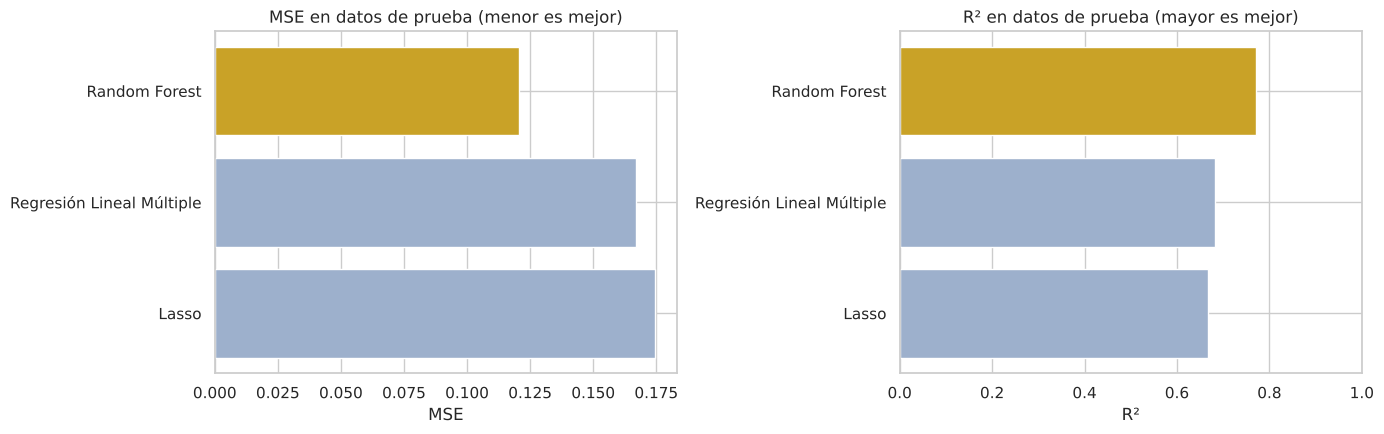

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
orden = metricas.index
axes[0].barh(orden, metricas['MSE'], color=['#C9A227' if i == 0 else '#9DB0CC' for i in range(len(orden))])
axes[0].invert_yaxis(); axes[0].set_title('MSE en datos de prueba (menor es mejor)'); axes[0].set_xlabel('MSE')
axes[1].barh(orden, metricas['R²'], color=['#C9A227' if i == 0 else '#9DB0CC' for i in range(len(orden))])
axes[1].invert_yaxis(); axes[1].set_title('R² en datos de prueba (mayor es mejor)'); axes[1].set_xlabel('R²'); axes[1].set_xlim(0, 1)
plt.tight_layout(); plt.show()

**Interpretación:**
- En los datos de prueba, **Random Forest es el mejor modelo**: tiene el MSE más bajo (≈ 0.121) y el R² más alto (≈ 0.77), y se equivoca en promedio ±0.35 % vol (RMSE). La regresión lineal (MSE ≈ 0.167, R² ≈ 0.68) y Lasso (MSE ≈ 0.174, R² ≈ 0.67) quedan muy cerca entre sí, aunque Lasso usa solo 5 variables.
- **Random Forest muestra sobreajuste**: explica el 93% de la variación en entrenamiento, pero solo el 77% en prueba. Los modelos lineales no se sobreajustan: su R² en entrenamiento (0.53–0.57) incluso es menor que en prueba, otra señal de que los 36 vinos de prueba resultaron "fáciles".
- Con **validación cruzada** el R² baja a ≈ 0.51–0.55 (MSE ≈ 0.30–0.33) en los tres modelos. Esto significa que la división de prueba fue favorable y que el desempeño realista es moderado. Random Forest sigue en primer lugar, pero la diferencia con los modelos lineales (≈ 0.03–0.04 de R²) es menor que la variación entre particiones (desviación ≈ 0.09–0.13). La ventaja de Random Forest existe, pero es pequeña.

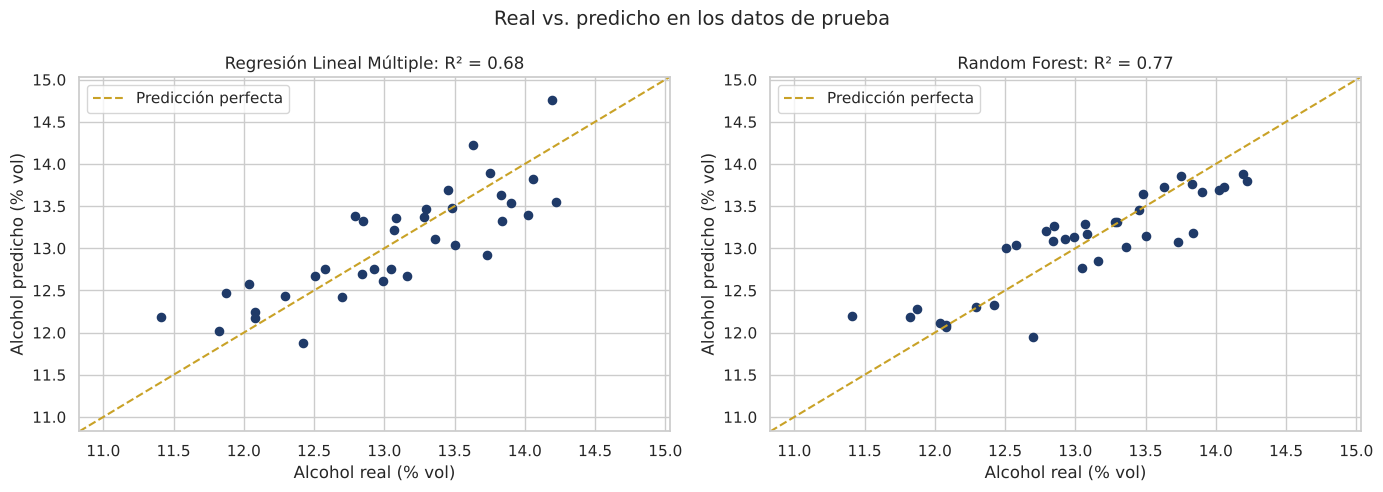

In [19]:
mejor = metricas.index[0]
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, nombre in zip(axes, ['Regresión Lineal Múltiple', mejor if mejor != 'Regresión Lineal Múltiple' else 'Random Forest']):
    p = predicciones[nombre]
    ax.scatter(y_test, p, color='#1F3A68', s=35)
    lim = [y.min() - 0.2, y.max() + 0.2]
    ax.plot(lim, lim, '--', color='#C9A227', label='Predicción perfecta')
    ax.set_xlim(lim); ax.set_ylim(lim)
    ax.set_xlabel('Alcohol real (% vol)'); ax.set_ylabel('Alcohol predicho (% vol)')
    ax.set_title(f'{nombre}: R² = {r2_score(y_test, p):.2f}'); ax.legend()
plt.suptitle('Real vs. predicho en los datos de prueba', fontsize=14); plt.tight_layout(); plt.show()

**Interpretación:** en ambos modelos los puntos siguen la diagonal de predicción perfecta, aunque con dispersión. Random Forest se ajusta más a la diagonal, pero "comprime" los extremos: sus predicciones van de ≈ 11.9 a 13.9 % vol, mientras que el alcohol real en prueba va de 11.4 a 14.2 % vol. Es decir, le cuesta predecir los vinos con alcohol muy bajo o muy alto.

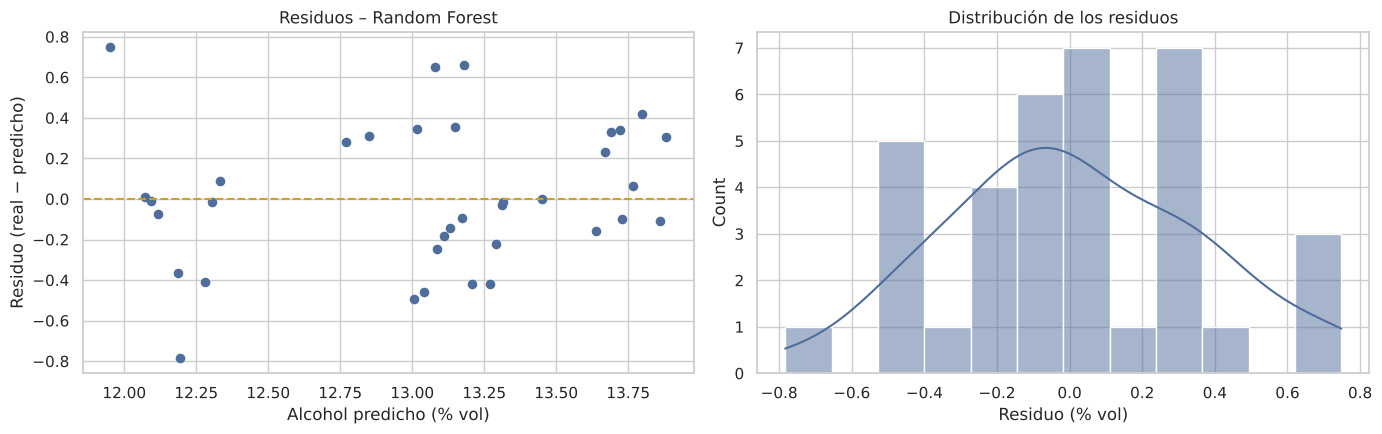

Error máximo: 0.78 % vol | Errores menores a 0.5 % vol: 89%


In [20]:
residuos = y_test - predicciones[mejor]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].scatter(predicciones[mejor], residuos, color='#4F6D9A', s=35); axes[0].axhline(0, color='#C9A227', ls='--')
axes[0].set_xlabel('Alcohol predicho (% vol)'); axes[0].set_ylabel('Residuo (real − predicho)'); axes[0].set_title(f'Residuos – {mejor}')
sns.histplot(residuos, bins=12, kde=True, color='#4F6D9A', ax=axes[1]); axes[1].set_title('Distribución de los residuos'); axes[1].set_xlabel('Residuo (% vol)')
plt.tight_layout(); plt.show()
print(f'Error máximo: {residuos.abs().max():.2f} % vol | Errores menores a 0.5 % vol: {(residuos.abs() < 0.5).mean():.0%}')

**Interpretación:** los residuos de Random Forest se reparten arriba y abajo de cero, sin forma de embudo. Esto significa que el error no crece al aumentar el alcohol predicho y que no hay un sesgo general (residuo promedio ≈ 0). El error máximo es de 0.78 % vol y el 89% de las predicciones se equivoca por menos de 0.5 % vol. El histograma de residuos está centrado cerca de 0; se ve irregular porque solo hay 36 vinos de prueba. Como se vio en la gráfica anterior, el modelo tiende a **sobreestimar los vinos de bajo alcohol y subestimar los de alto alcohol**, porque Random Forest promedia valores de entrenamiento y no puede predecir fuera de ese rango.

## 8. Exportación para RapidMiner
Se exportan los datos limpios (sin `Muestra` y con nombres corregidos, usando `_` en lugar de espacios) como `vino_rapidminer.csv`. Ese archivo lo lee el proceso de RapidMiner `Equipo 7 Practica 3.3 Regresion.rmp`.

**Proceso en RapidMiner:** Read CSV → Set Role (`Alcohol` como *label*) → Split Data (80/20, semilla 42) → **Linear Regression** (sin selección de variables, igual que en Python) y **Random Forest** (300 árboles, criterio *least square*) → Apply Model → Performance (Regression). También incluye *Weight by Correlation*, para la correlación de cada variable con el alcohol, y los pesos de Random Forest, para la importancia de las variables.

**Cómo leer las métricas de RapidMiner:**

| Python | RapidMiner (Performance) |
|---|---|
| MSE | `squared_error` |
| RMSE | `root_mean_squared_error` |
| MAE | `absolute_error` |
| R² | **1 − (`root_relative_squared_error`)²** |

`squared_correlation` es el cuadrado de la correlación entre el valor real y el predicho. **No es el mismo R²** que calcula `r2_score`, y en datos de prueba suele salir un poco más alto. Además, la división 80/20 de RapidMiner no es la misma que la de Python, así que los valores serán parecidos pero no idénticos.

In [21]:
exportar = datos.copy()
exportar.columns = [c.replace(' ', '_') for c in exportar.columns]
exportar.to_csv('vino_rapidminer.csv', index=False)
print('Archivo generado: vino_rapidminer.csv', exportar.shape, '| columnas:', list(exportar.columns))
try:
    from google.colab import files
    files.download('vino_rapidminer.csv')
except ImportError:
    print('No es Colab; el archivo quedó en la misma carpeta que el notebook')

Archivo generado: vino_rapidminer.csv (178, 13) | columnas: ['Alcohol', 'Acido_Malico', 'Ceniza', 'Ceniza_Alcalina', 'Magnesio', 'Fenoles', 'Flavonoides', 'Fenoles_No_Flavonoides', 'Protocianinas', 'Color_Intenso', 'Matiz', 'Concentracion_Proteinas', 'Prolina']
No es Colab; el archivo quedó en la misma carpeta que el notebook


## 9. Conclusiones

1. **Variables de mayor participación: Color Intenso y Prolina.** Son las más correlacionadas con el alcohol
   (r = 0.55 y 0.64), las de mayor coeficiente en la regresión lineal y en Lasso, y juntas suman el **63% de la
   importancia en Random Forest** (42% y 21%). Les siguen, con mucho menor peso, Ceniza Alcalina (relación negativa)
   y Ácido Málico.
2. **Lasso confirmó la selección:** de 12 variables conservó solo 5 (Color Intenso, Prolina, Ceniza Alcalina,
   Ácido Málico y Fenoles) y llevó a cero las otras 7, con casi el mismo error que la regresión lineal completa.
   Quitar variables solo por su correlación simple no mejoró el modelo (validación cruzada en entrenamiento).
3. **Mejor modelo: Random Forest.** En los datos de prueba obtuvo **MSE = 0.121** y **R² = 0.77**: explica el 77% de la
   variación del alcohol y se equivoca en promedio ±0.35% vol (RMSE). El 89% de sus predicciones tiene un error menor
   a 0.5% vol. La regresión lineal y Lasso quedaron cerca entre sí (R² ≈ 0.67–0.68, MSE ≈ 0.17): Lasso logra casi lo mismo
   con menos variables.
4. **Validación cruzada:** con 5 particiones, el R² promedio baja a **0.51–0.55** (MSE ≈ 0.30–0.33). La división de prueba fue
   favorable; el desempeño realista esperado es **moderado**: el modelo explica alrededor de la mitad de la
   variación del alcohol. Random Forest sigue siendo el mejor, pero por un margen pequeño frente a la variación entre
   particiones, y muestra sobreajuste (R² = 0.93 en entrenamiento).
5. **Para el negocio:** el color y la prolina sirven como indicadores tempranos del grado de alcohol. El modelo es útil
   para **estimar** el alcohol y detectar lotes fuera de lo esperado, pero no sustituye la medición de laboratorio,
   sobre todo en vinos de alcohol muy bajo o muy alto, donde tiende a acercar la predicción al promedio.
6. **Limitaciones:** solo hay 178 muestras, y el alcohol depende de factores que no están en los datos (azúcar de la
   uva, tiempo y temperatura de fermentación). Con más muestras y esas variables el modelo podría mejorar.